### Notebook de la clase: Datos multidimensionales con xarray y un análisis reproducible
*28.09.2026*

In [4]:
pip install netcdf4

   ---------------------------------------- 0.0/21.3 MB ? eta -:--:--
   ---------------------------------------- 0.3/21.3 MB ? eta -:--:--
   - -------------------------------------- 0.8/21.3 MB 2.2 MB/s eta 0:00:10
   -- ------------------------------------- 1.3/21.3 MB 2.3 MB/s eta 0:00:09
   --- ------------------------------------ 1.8/21.3 MB 2.3 MB/s eta 0:00:09
   ---- ----------------------------------- 2.4/21.3 MB 2.4 MB/s eta 0:00:08
   ----- ---------------------------------- 2.9/21.3 MB 2.4 MB/s eta 0:00:08
   ------ --------------------------------- 3.4/21.3 MB 2.4 MB/s eta 0:00:08
   ------- -------------------------------- 3.9/21.3 MB 2.4 MB/s eta 0:00:08
   -------- ------------------------------- 4.5/21.3 MB 2.5 MB/s eta 0:00:07
   --------- ------------------------------ 5.0/21.3 MB 2.5 MB/s eta 0:00:07
   ---------- ----------------------------- 5.5/21.3 MB 2.5 MB/s eta 0:00:07
   ----------- ---------------------------- 6.0/21.3 MB 2.5 MB/s eta 0:00:07
   ----------

In [1]:
import xarray as xr  #Nos ayuda a leer archivos NETCDF
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ds = xr.open_dataset("../data/sst_baja_1981_2026.nc", engine = "netcdf4")  #Para abrir nuestro archivo

In [7]:
ds  #Para ver el dataset de los datos que cargamos 

<xarray.Dataset> Size: 17MB
Dimensions:  (time: 540, lat: 58, lon: 66)
Coordinates:
  * time     (time) datetime64[ns] 4kB 1981-09-01 1981-10-01 ... 2026-08-01
  * lat      (lat) float32 232B 21.12 21.38 21.62 21.88 ... 34.88 35.12 35.38
  * lon      (lon) float32 264B -124.9 -124.6 -124.4 ... -109.1 -108.9 -108.6
Data variables:
    sst      (time, lat, lon) float32 8MB ...
    ssta     (time, lat, lon) float32 8MB ...
Attributes: (12/15)
    description:                ENSO related variables. Monthly. Oceanic Nino...
    title:                      Monthly sea surface temperature and SST anoma...
    summary:                    Monthly sea surface temperature (SST) and sea...
    source:                     NOAA Optimum Interpolation Sea Surface Temper...
    institution:                CICESE
    Conventions:                CF-1.8
    ...                         ...
    geospatial_lat_min:         21.125
    geospatial_lat_max:         35.375
    geospatial_lon_min:         -124.875
    geospatial_lon_max:         -108.625
    geospatial_lat_resolution:  0.25
    geospatial_lon_resolution:  0.25

In [8]:
ds.attrs #Sólo nos da los atributos

{'description': 'ENSO related variables. Monthly. Oceanic Nino (ONI), NOAA OISST, Rain Ensenada Dam',
 'title': 'Monthly sea surface temperature and SST anomaly around Baja California',
 'summary': 'Monthly sea surface temperature (SST) and sea surface temperature anomaly (SSTA) for a regional domain around Baja California. SST data are from NOAA OISST V2.1. Prepared for the 2026 CICESE Physical Oceanography introductory scientific computing minicourse.',
 'source': 'NOAA Optimum Interpolation Sea Surface Temperature (OISST) Version 2.1',
 'institution': 'CICESE',
 'Conventions': 'CF-1.8',
 'history': '2026-09-16: Course dataset created from Datos_cursoPython_2026.nc; ONI and precipitation were exported to separate CSV files.',
 'time_coverage_start': '1981-09-01',
 'time_coverage_end': '2026-08-01',
 'geospatial_lat_min': np.float64(21.125),
 'geospatial_lat_max': np.float64(35.375),
 'geospatial_lon_min': np.float64(-124.875),
 'geospatial_lon_max': np.float64(-108.625),
 'geospatial

In [9]:
ds.sst #Te da los datos relevantes de la variable SST


<xarray.DataArray 'sst' (time: 540, lat: 58, lon: 66)> Size: 8MB
[2067120 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 4kB 1981-09-01 1981-10-01 ... 2026-08-01
  * lat      (lat) float32 232B 21.12 21.38 21.62 21.88 ... 34.88 35.12 35.38
  * lon      (lon) float32 264B -124.9 -124.6 -124.4 ... -109.1 -108.9 -108.6
Attributes:
    long_name:      Monthly mean sea surface temperature
    standard_name:  sea_surface_temperature
    units:          degree_Celsius
    source:         NOAA OISST V2.1
    cell_methods:   time: mean

In [10]:
type(ds)
type(ds.sst)
	#Qué tipo de variable es

xarray.core.dataarray.DataArray

In [11]:
ds.sst.dims #Dimensiones de SST

('time', 'lat', 'lon')

In [12]:
ds.sst.shape #Cuáles dimensiones tiene 

(540, 58, 66)

In [13]:
#Para seleccionar un valor de una variable. . .
ds.sst.isel(time = 0) 

<xarray.DataArray 'sst' (lat: 58, lon: 66)> Size: 15kB
[3828 values with dtype=float32]
Coordinates:
  * lat      (lat) float32 232B 21.12 21.38 21.62 21.88 ... 34.88 35.12 35.38
  * lon      (lon) float32 264B -124.9 -124.6 -124.4 ... -109.1 -108.9 -108.6
    time     datetime64[ns] 8B 1981-09-01
Attributes:
    long_name:      Monthly mean sea surface temperature
    standard_name:  sea_surface_temperature
    units:          degree_Celsius
    source:         NOAA OISST V2.1
    cell_methods:   time: mean

In [16]:
ds.sst.sel(time = "1997-12") #Una fecha en específico
    #ds.sst.sel(time = [“ ”,” ”]) #Para dos o más fechas

<xarray.DataArray 'sst' (time: 1, lat: 58, lon: 66)> Size: 15kB
[3828 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 8B 1997-12-01
  * lat      (lat) float32 232B 21.12 21.38 21.62 21.88 ... 34.88 35.12 35.38
  * lon      (lon) float32 264B -124.9 -124.6 -124.4 ... -109.1 -108.9 -108.6
Attributes:
    long_name:      Monthly mean sea surface temperature
    standard_name:  sea_surface_temperature
    units:          degree_Celsius
    source:         NOAA OISST V2.1
    cell_methods:   time: mean

In [18]:
baja_norte = ds.ssta.sel(lat = slice(28,33), lon = slice(-120,-115))
baja_norte

<xarray.DataArray 'ssta' (time: 540, lat: 20, lon: 20)> Size: 864kB
[216000 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 4kB 1981-09-01 1981-10-01 ... 2026-08-01
  * lat      (lat) float32 80B 28.12 28.38 28.62 28.88 ... 32.38 32.62 32.88
  * lon      (lon) float32 80B -119.9 -119.6 -119.4 ... -115.6 -115.4 -115.1
Attributes:
    long_name:     Monthly sea surface temperature anomaly
    units:         degree_Celsius
    source:        NOAA OISST V2.1
    cell_methods:  time: mean
    comment:       Anomaly field retained from the original course dataset. T...

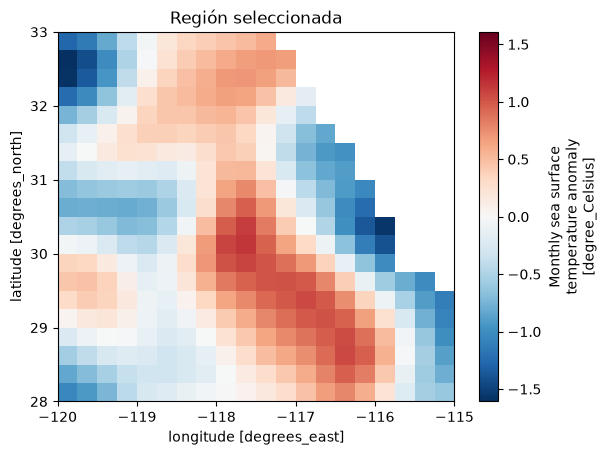

In [19]:
baja_norte.isel(time=0).plot()
plt.title("Región seleccionada")
plt.show()

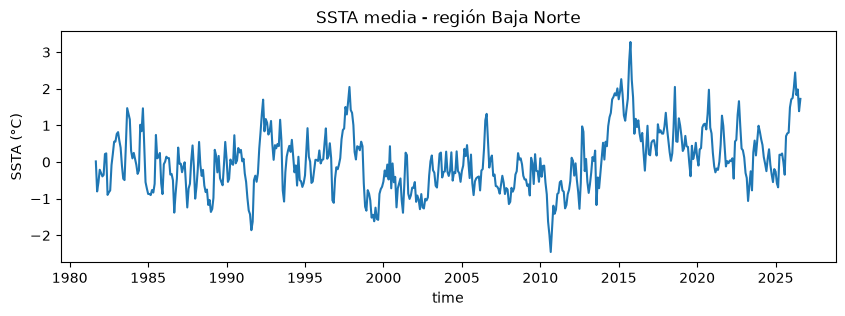

In [20]:
baja_norte.mean(("lat", "lon"), skipna=True).plot(figsize=(10, 3))
plt.ylabel("SSTA (°C)")
plt.title("SSTA media - región Baja Norte")
plt.show()

In [38]:
## Hacer un punete de pandas a xarray 

ssta_series = baja_norte.mean (dim = ("lat","lon"), skipna = True)
#ssta_series 

#Para convertirlo a pandas 
ssta_series = ssta_series.to_series()  #convierte todo lo que tengas a una serie de pandas para poder comparar
type (ssta_series)

pandas.Series

In [39]:
oni = pd.read_csv("../data/oni_mensual_1981_2026.csv", parse_dates = ["time"])

prep = pd.read_csv("../data/precipitacion_ensenada_1981_2026.csv", parse_dates = ["time"])

In [40]:
oni = oni.set_index("time")  #Ahora el indice de mis datos seran las fechas
prep = prep.set_index("time")

In [42]:
analisis = pd.concat(
    [
        ssta_series.rename("ssta_degC"),
        oni["oni_degC"],
        prep["precip_mm"]
    ],

    axis = 1
)

analisis.head()
    #Aquí concatenamos para 

,ssta_degC,oni_degC,precip_mm
time,,,
1981-09-01,0.017456,-0.25,2.0
1981-10-01,-0.801558,-0.16,5.0
1981-11-01,-0.548439,-0.13,68.5
1981-12-01,-0.210056,-0.15,20.0
1982-01-01,-0.300845,-0.08,54.8


In [46]:
analisis.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 540 entries, 1981-09-01 to 2026-08-01
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ssta_degC  540 non-null    float32
 1   oni_degC   540 non-null    float64
 2   precip_mm  511 non-null    float64
dtypes: float32(1), float64(2)
memory usage: 14.8 KB


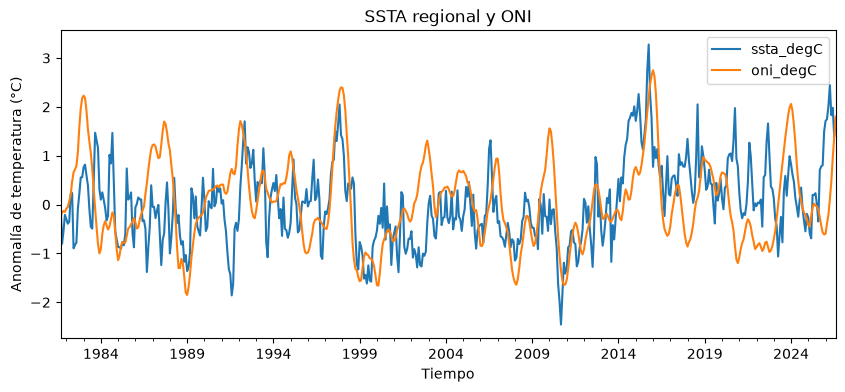

In [45]:
analisis[["ssta_degC", "oni_degC"]].plot(figsize=(10, 4))
plt.ylabel("Anomalía de temperatura (°C)")
plt.xlabel("Tiempo")
plt.title("SSTA regional y ONI")
plt.show()

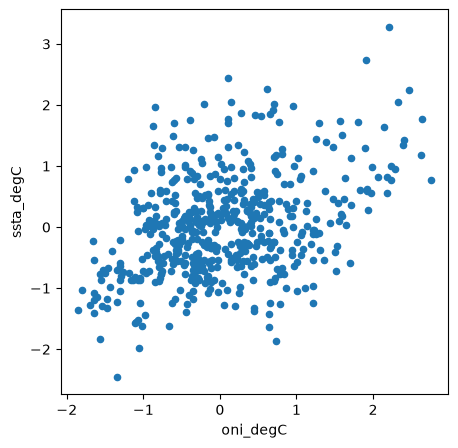

In [51]:
analisis.plot.scatter(x = "oni_degC", y = "ssta_degC", figsize = (5,5))
plt.show()

In [53]:
analisis[["oni_degC", "ssta_degC"]].corr()

,oni_degC,ssta_degC
oni_degC,1.000000,0.390292
ssta_degC,0.390292,1.000000


In [57]:
def regional_mean(da,lat_range, lon_range):
    """ Calcula la media espacial de un DataArray en una región rectangular. 
    Parametros
    ____________
    da : xarray.DataArray
        Campo con dimensiones lat y lon 
    lat_range : tuple 
        (lat_min, lat_max)
    lon_range : tuple
        (lon_min, lot_max)

    Returns
    __________
    xarray.Datarray
        Serie resultante después de promediar lat y lon.
    
    """
    region = da.sel(lat = slice(*lat_range), lon = slice(*lon_range))

    return(region.mean(dim = ("lat", "lon"), skipna = True))

In [58]:
baja_series = regional_mean(ds.ssta, (28,33), (-120,-115))
baja_series

<xarray.DataArray 'ssta' (time: 540)> Size: 2kB
array([ 1.74564160e-02, -8.01558197e-01, -5.48438787e-01, -2.10056201e-01,
       -3.00844878e-01, -3.91321152e-01, -3.51450324e-01,  2.18306631e-01,
        2.36718208e-01, -8.96373689e-01, -8.26660514e-01, -7.74362922e-01,
       -8.32917541e-02,  2.16435254e-01,  5.55345178e-01,  5.58817208e-01,
        7.67568827e-01,  8.17435920e-01,  5.92509389e-01,  3.92195582e-01,
       -8.96406993e-02, -4.53420550e-01, -4.91134137e-01,  4.46056247e-01,
        1.47094560e+00,  1.31415939e+00,  1.16202915e+00,  3.07478607e-01,
        1.01089582e-01,  2.49819666e-01,  9.59187672e-02, -7.72193447e-02,
       -3.22561711e-01, -2.27311581e-01,  1.01847410e+00,  8.41802597e-01,
        1.46675611e+00,  4.73688900e-01, -5.48028052e-01, -7.17218101e-01,
       -8.69918585e-01, -8.71838868e-01, -9.00755703e-01, -7.64285564e-01,
       -8.32358479e-01, -5.95172942e-01,  7.39920318e-01,  1.02240585e-01,
        1.37973234e-01,  2.48553261e-01, -5.81110537e-01, -8.74161959e-01,
       -5.98022267e-02,  1.37858000e-02,  1.45766810e-01,  1.06481969e-01,
        1.07414640e-01, -3.40419650e-01, -3.23842049e-01, -4.98340487e-01,
       -1.37972903e+00, -8.75574112e-01, -4.53465253e-01,  3.95062685e-01,
       -4.71810848e-02, -4.68279608e-02, -2.77384013e-01, -1.24894202e-01,
       -6.47406606e-03, -6.33568466e-01, -1.23914349e+00, -7.22683966e-01,
       -5.93612790e-01,  3.84082384e-02,  4.53453034e-01, -1.12486862e-01,
       -9.98680532e-01, -6.73011720e-01, -2.05730632e-01,  5.48982501e-01,
...
        9.45368707e-01,  1.02782607e+00,  1.04618251e+00,  8.91335964e-01,
        1.31337094e+00,  1.97421849e+00,  9.42699850e-01,  7.82236397e-01,
        2.48114347e-01, -1.15848340e-01, -2.80837715e-01, -1.76299915e-01,
       -2.12682039e-01,  8.36434774e-03,  4.68366623e-01,  1.26603842e+00,
        9.86229181e-01,  4.25968647e-01, -1.18900582e-01,  2.46720091e-02,
       -3.01908590e-02,  4.35215198e-02,  2.52360944e-02,  1.03148624e-01,
       -4.52163190e-01,  5.62318325e-01,  6.03779495e-01,  1.29020143e+00,
        1.66140044e+00,  9.86985683e-01,  3.67624372e-01,  3.21864456e-01,
        1.28840417e-01, -2.97220111e-01, -4.33409423e-01, -1.06257606e+00,
       -6.39319062e-01, -2.51341134e-01, -7.72708714e-01,  2.68216729e-01,
        5.86270988e-01,  1.81181297e-01,  6.09207451e-01,  9.90591884e-01,
        8.24549317e-01,  6.18465662e-01,  4.67631251e-01,  1.33606359e-01,
       -4.22421023e-02, -2.48348311e-01,  9.76257995e-02,  3.48739564e-01,
       -7.58259296e-02, -3.32571298e-01, -5.47031045e-01, -1.91240966e-01,
       -2.62534738e-01, -5.87881923e-01, -6.90237880e-01,  1.99982464e-01,
        1.95412084e-01,  2.33372405e-01, -7.88965728e-04, -3.45169932e-01,
        7.07026303e-01,  7.82383800e-01,  8.04951608e-01,  1.49029386e+00,
        1.71222687e+00,  1.74768174e+00,  2.01705718e+00,  2.44491124e+00,
        1.82997346e+00,  1.98151922e+00,  1.38823926e+00,  1.72411776e+00],
      dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 4kB 1981-09-01 1981-10-01 ... 2026-08-01
Attributes:
    long_name:     Monthly sea surface temperature anomaly
    units:         degree_Celsius
    source:        NOAA OISST V2.1
    cell_methods:  time: mean
    comment:       Anomaly field retained from the original course dataset. T...